# Shazam from Scratch 🎵
### HKN Inductee Workshop

> **The idea:** Shazam turns audio into a *constellation* of spectrogram peaks, hashes **pairs** of peaks into fingerprints, and identifies a song by finding the track whose fingerprints agree on **one consistent time offset**.

In about 25 minutes of coding you'll build a working audio fingerprinter that recognizes a noisy 5-second clip.

| Part | What you build | TODO |
|---|---|---|
| 1 | Spectrogram → **constellation map** of peaks | `find_peaks` |
| 2 | Hashes from **pairs** of peaks | `fingerprint` |
| 3 | Database + **offset voting** | `vote` |
| 4 | Stress test | (just run it) |

Most of the code is already written. Fill in the 3 **✏️ TODO** cells and run the ✅ check below each one. If you get stuck, open the *Stuck?* box and keep going.

Run cells top-to-bottom with **Shift+Enter**.

In [1]:
# Setup: run this first
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict, Counter
from scipy.signal import spectrogram, sosfiltfilt, butter, fftconvolve, resample
from scipy.ndimage import maximum_filter
from IPython.display import Audio, display

FS = 11025          # sample rate (Hz). Low on purpose so everything runs in seconds
NPERSEG = 1024      # FFT window length -> ~10.8 Hz per frequency bin
HOP = 512           # step between windows -> ~46 ms per time frame
FRAME_SEC = HOP / FS

# Plot style: quiet axes so the data stands out
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": "#0b0b0b",
    "xtick.color": GREY, "ytick.color": GREY,
    "axes.titlesize": 12, "axes.titleweight": "bold",
})

def play(x):
    """Show an audio player for signal x."""
    display(Audio(x, rate=FS, normalize=True))

print("Ready ✔")

Ready ✔


## 0 · Our music library

This cell **synthesizes** 8 original songs, so there's nothing to download. *You don't need to read it.*

> Want real music? Set `USE_REAL_AUDIO = True` and put `.wav`/`.mp3` files in a `songs/` folder. In Colab, use the 📁 sidebar to upload them. Everything downstream works unchanged.

In [2]:
USE_REAL_AUDIO = False
AUDIO_DIR = "songs"

In [3]:
# ----------------------------------
# Synthesized music generation (feel free to skip reading this cell) 
# I don't understand the syntethic music generation either :(
# ----------------------------------

SONG_NAMES = ["Fourier Nights", "Nyquist Shuffle", "Aliasing Blues", "Phase-Locked Love",
              "Bode to Joy", "Lowpass Lullaby", "Eigen Groove", "Midnight Modem"]
SONG_SECONDS = 30
SCALES = {"major": [0, 2, 4, 5, 7, 9, 11], "minor": [0, 2, 3, 5, 7, 8, 10],
          "pentatonic": [0, 2, 4, 7, 9], "dorian": [0, 2, 3, 5, 7, 9, 10]}

def _note(freq, dur, harmonics, decay):
    t = np.arange(int(dur * FS)) / FS
    vibrato = 1 + 0.003 * np.sin(2 * np.pi * 5 * t)
    y = sum(a * np.sin(2 * np.pi * freq * (k + 1) * t * vibrato) for k, a in enumerate(harmonics))
    return y * np.minimum(1, t / 0.01) * np.exp(-decay * t / dur)

def make_song(seed, seconds=SONG_SECONDS):
    rng = np.random.default_rng(seed)
    beat = 60 / rng.integers(80, 150)
    scale = np.array(SCALES[rng.choice(list(SCALES))])
    scale = np.concatenate([scale, scale + 12])
    root = rng.integers(45, 57)
    lead = rng.dirichlet(np.ones(5)) * rng.uniform(1, 2)      # per-song timbre
    pad = rng.dirichlet(np.ones(3))
    progression = rng.choice(len(scale) // 2, size=4)
    out = np.zeros(int((seconds + 2) * FS))
    t = 0.0
    while t < seconds:
        i = int(t * FS)
        # chord + bass on every beat
        deg = progression[int(t / (4 * beat)) % 4]
        for off in (0, 2, 4):
            f = 440 * 2 ** ((root + scale[deg + off] - 69) / 12)
            seg = 0.25 * _note(f, beat, pad, 2)
            out[i:i + len(seg)] += seg
        seg = 0.5 * _note(440 * 2 ** ((root - 12 + scale[deg] - 69) / 12), beat, [1, .4], 3)
        out[i:i + len(seg)] += seg
        # melody: random rhythm of 8th / 16th / quarter notes
        sub = 0.0
        while sub < beat - 1e-9:
            dur = beat * rng.choice([0.25, 0.5, 0.5, 1.0])
            if rng.random() > 0.15:
                f = 440 * 2 ** ((root + 12 + rng.choice(scale) - 69) / 12)
                seg = 0.6 * _note(f, dur, lead, 3)
                j = i + int(sub * FS)
                out[j:j + len(seg)] += seg
            sub += dur
        # hi-hat
        hh = rng.standard_normal(int(0.03 * FS)) * np.exp(-np.arange(int(0.03 * FS)) / (0.004 * FS))
        out[i:i + len(hh)] += 0.15 * hh
        t += beat
    out = out[:int(seconds * FS)]
    out += 10 ** (-30 / 20) * np.sqrt(np.mean(out ** 2)) * rng.standard_normal(len(out))  # faint hiss, like a real recording
    return out / np.abs(out).max()

In [4]:
# ----------------------------------
# Load audio
# ----------------------------------

def load_audio(path, seconds=SONG_SECONDS):
    """Load an audio file as mono at FS (uses librosa, which Colab has preinstalled)."""
    import librosa
    x, _ = librosa.load(path, sr=FS, mono=True, duration=seconds)
    return x / (np.abs(x).max() + 1e-12)

if USE_REAL_AUDIO:
    from pathlib import Path
    files = sorted(p for p in Path(AUDIO_DIR).iterdir() if p.suffix.lower() in {".wav", ".mp3", ".flac", ".ogg"})
    SONG_NAMES = [p.stem for p in files]
    songs = [load_audio(p) for p in files]
else:
    songs = [make_song(seed) for seed in range(len(SONG_NAMES))]

for i, name in enumerate(SONG_NAMES):
    print(f"  [{i}] {name}  ({len(songs[i]) / FS:.0f} s)")

  [0] Fourier Nights  (30 s)
  [1] Nyquist Shuffle  (30 s)
  [2] Aliasing Blues  (30 s)
  [3] Phase-Locked Love  (30 s)
  [4] Bode to Joy  (30 s)
  [5] Lowpass Lullaby  (30 s)
  [6] Eigen Groove  (30 s)
  [7] Midnight Modem  (30 s)


In [5]:
play(songs[1])   # 🎧 a masterpiece

### The query: a short, noisy, time-shifted clip

This is what a phone hears: **5 seconds** from **somewhere** in a song, buried in noise. `make_query` is the "mystery clip" generator we'll use all session.

In [6]:
def add_noise(x, snr_db, rng=None):
    """Add white noise at a given signal-to-noise ratio (dB). 0 dB means noise is as loud as the music."""
    rng = np.random.default_rng(rng)
    noise = rng.standard_normal(len(x))
    noise *= np.sqrt(np.mean(x ** 2) / 10 ** (snr_db / 10) / np.mean(noise ** 2))
    return x + noise

def make_query(song_id, start_sec, seconds=5, snr_db=0, rng=None):
    start = int(start_sec * FS)
    return add_noise(songs[song_id][start:start + int(seconds * FS)], snr_db, rng)

# A random song and start time: pretend we don't know these!
SECRET_SONG = np.random.randint(len(songs))
SECRET_START = round(np.random.uniform(0, len(songs[SECRET_SONG]) / FS - 5), 1)   # leave room for a 5 s clip
query = make_query(SECRET_SONG, SECRET_START, snr_db=0, rng=0)
play(query)

---
## Part 1 · From audio to a constellation map

A **spectrogram** is a heatmap: time on x, frequency on y, color = energy (in dB). We compute it with a short-time FFT (Fast-Fourier Transform): 1024-sample windows that step forward 512 samples at a time.

S_song shape (freq bins, time frames): (513, 644)


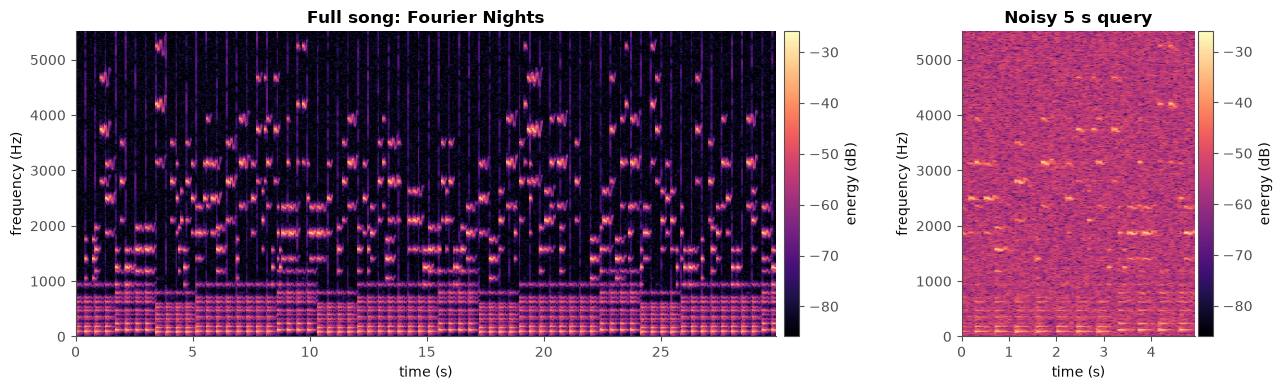

In [7]:
def compute_spectrogram(x):
    """Returns (freqs_hz, times_sec, Spectrogram_db) where Spectrogram_db has shape (n_freq_bins, n_time_frames)."""
    f, t, S = spectrogram(x, fs=FS, nperseg=NPERSEG, noverlap=NPERSEG - HOP)
    return f, t, 10 * np.log10(S + 1e-10)

def plot_spectrogram(Spectrogram_db, title="", ax=None, peaks=None, max_hz=FS / 2):
    ax = ax or plt.gca()
    n_freq, n_time = Spectrogram_db.shape
    hz_per_bin = FS / NPERSEG
    vmax = Spectrogram_db.max()
    im = ax.imshow(Spectrogram_db, origin="lower", aspect="auto", cmap="magma", vmin=vmax - 60, vmax=vmax,
                   extent=[0, n_time * FRAME_SEC, 0, n_freq * hz_per_bin])
    ax.figure.colorbar(im, ax=ax, label="energy (dB)", pad=0.01)
    if peaks is not None and len(peaks):
        ax.scatter(peaks[:, 1] * FRAME_SEC, peaks[:, 0] * hz_per_bin, s=14, c=AQUA,
                   edgecolors="white", linewidths=0.6, label=f"{len(peaks)} peaks")
        ax.legend(loc="upper right", frameon=False)
    ax.set(ylim=(0, max_hz), xlabel="time (s)", ylabel="frequency (Hz)", title=title)

f, t, S_song = compute_spectrogram(songs[SECRET_SONG])
_, _, S_query = compute_spectrogram(query)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [3, 1]})
plot_spectrogram(S_song, f"Full song: {SONG_NAMES[SECRET_SONG]}", axes[0])
plot_spectrogram(S_query, "Noisy 5 s query", axes[1])
plt.tight_layout()
print("S_song shape (freq bins, time frames):", S_song.shape)

Notice how the noise fills in the background of the query, but the **bright spots** still stand out. Those bright spots are what we'll keep.

### ✏️ TODO 1: `find_peaks`

A point is a **peak** if it is
1. the **maximum of its neighborhood**, meaning no louder point within ±10 bins in frequency and ±10 frames in time, **and**
2. **loud enough**, meaning more than `threshold_db` above the spectrogram's mean, so quiet background bumps don't count.

Tools:
- `maximum_filter(Spectrogram_db, size=neighborhood)` returns an array where every pixel holds the max of its neighborhood. So `maximum_filter(Spectrogram_db, ...) == Spectrogram_db` returns the local maxima.
- `np.argwhere(mask)` returns the `(row, col)` = `(freq_idx, time_idx)` of every `True`.
- **Sort the peaks by time**, since Part 2 depends on it. `peaks[np.argsort(peaks[:, 1], kind="stable")]` does this.

In [8]:
def find_peaks(Spectrogram_db, neighborhood=(20, 20), threshold_db=10):
    """Return an int array of shape (n_peaks, 2): columns are (freq_idx, time_idx), sorted by time."""
    local_max = maximum_filter(Spectrogram_db, size=neighborhood) == Spectrogram_db
    loud = Spectrogram_db > Spectrogram_db.mean() + threshold_db
    peaks = np.argwhere(local_max & loud)
    return peaks[np.argsort(peaks[:, 1], kind="stable")] # stable ensures we have a predictable way of handling duplicates


✅ find_peaks works! Song: 394 peaks (13/s), query: 90 peaks


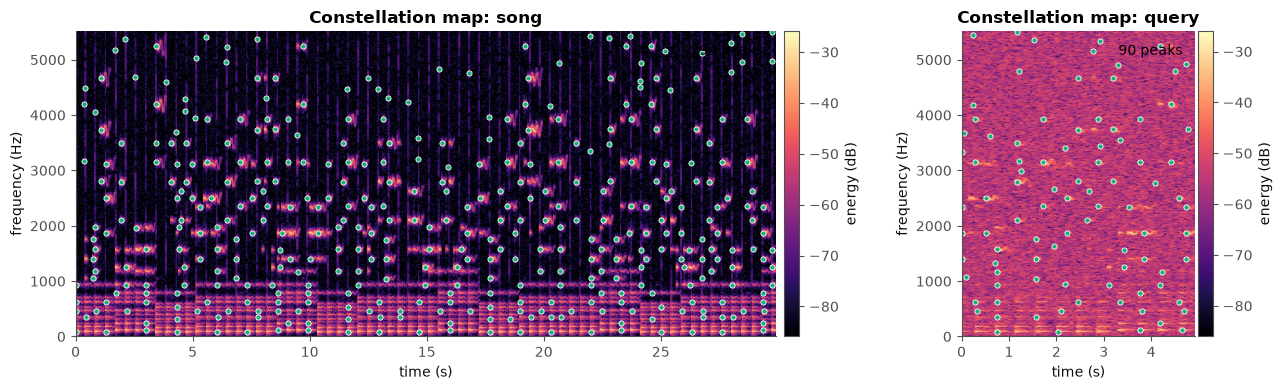

In [9]:
# ✅ Check TODO 1
S_test = np.zeros((50, 60))
S_test[10, 10], S_test[12, 12], S_test[30, 40], S_test[40, 5] = 20, 15, 25, 30
got = find_peaks(S_test, neighborhood=(20, 20), threshold_db=10)
assert isinstance(got, np.ndarray) and got.ndim == 2 and got.shape[1] == 2, "return an (n, 2) array"
assert got.tolist() == [[40, 5], [10, 10], [30, 40]], f"expected [[40,5],[10,10],[30,40]] (sorted by time), got {got.tolist()}"

song_peaks = find_peaks(S_song)
query_peaks = find_peaks(S_query)
print(f"✅ find_peaks works! Song: {len(song_peaks)} peaks ({len(song_peaks) / SONG_SECONDS:.0f}/s), query: {len(query_peaks)} peaks")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [3, 1]})
plot_spectrogram(S_song, "Constellation map: song", axes[0], peaks=song_peaks)
plot_spectrogram(S_query, "Constellation map: query", axes[1], peaks=query_peaks)
plt.tight_layout()

🌌 **That's the constellation map.** We've reduced 330,000 audio samples to a few hundred points, and these points are all we'll use from here on.

### Experiment: do peaks survive noise?

Below we add noise to the clean audio and check what fraction of the clean peaks still appear (within ±1 bin) in the noisy version. **Change `SNR_DB`** and re-run. Try 20, 10, 0, and −10.

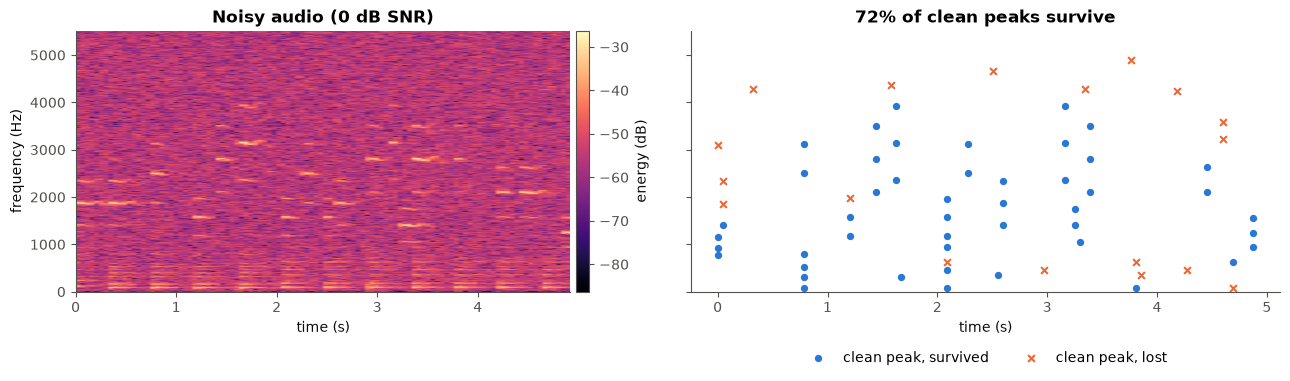

In [10]:
SNR_DB = 0      # 🔧 try 20, 0, -5, -10

clean = songs[SECRET_SONG][int(10 * FS):int(15 * FS)]
noisy = add_noise(clean, SNR_DB, rng=1)
p_clean = find_peaks(compute_spectrogram(clean)[2])
p_noisy = find_peaks(compute_spectrogram(noisy)[2])

noisy_set = {(fi + df, ti + dt) for fi, ti in p_noisy for df in (-1, 0, 1) for dt in (-1, 0, 1)}
survived = np.array([(fi, ti) in noisy_set for fi, ti in p_clean])

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
plot_spectrogram(compute_spectrogram(noisy)[2], f"Noisy audio ({SNR_DB} dB SNR)", axes[0])
hz, sec = FS / NPERSEG, FRAME_SEC
axes[1].scatter(p_clean[survived, 1] * sec, p_clean[survived, 0] * hz, s=18, c=BLUE, label="clean peak, survived")
axes[1].scatter(p_clean[~survived, 1] * sec, p_clean[~survived, 0] * hz, s=24, c=ORANGE, marker="x", label="clean peak, lost")
axes[1].set(xlabel="time (s)", title=f"{survived.mean():.0%} of clean peaks survive")
axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout()

### 🗣 Discuss
- At 0 dB we lose a lot of peaks, mostly the weak high-frequency ones. The strong notes survive at **exactly the same** positions. Why? *(White noise spreads its energy across every bin; a note concentrates its energy in a few.)*
- Is **one peak** `(freq, time)` enough to identify a song? *(No. Each frequency appears in many songs, and `time` depends on where the clip started.)*

---
## Part 2 · Fingerprints: hashing *pairs* of peaks

A single peak isn't distinctive, but a **pair** of peaks is:

$$\text{hash} = (f_1,\; f_2,\; \Delta t), \qquad \Delta t = t_2 - t_1$$

This hash contains **no absolute time**, so it's the same whether the clip starts at 0:00 or 2:37. We store the anchor time $t_1$ *next to* the hash for later.

Each peak (the *anchor*) pairs only with the next `fan_out` peaks after it, rather than with every peak, which would be $O(n^2)$.

### ✏️ TODO 2: `fingerprint`
For each anchor `(f1, t1)` at index `i`, loop over the targets `peaks[i+1 : i+1+fan_out]`. For each target `(f2, t2)`, if `0 < dt <= max_dt`, append `((f1, f2, dt), t1)`. 

Only keep positive ∆t's to ensure no duplicates.

In [11]:
def fingerprint(peaks, fan_out=10, max_dt=200):
    """Return a list of (hash_key, anchor_time) where hash_key = (f1, f2, dt)."""
    hashes = []
    for i, (f1, t1) in enumerate(peaks):
        for f2, t2 in peaks[i + 1:i + 1 + fan_out]:
            dt = t2 - t1
            if 0 < dt <= max_dt:
                hashes.append(((int(f1), int(f2), int(dt)), int(t1)))
    return hashes

✅ fingerprint works! The query has 767 hashes, e.g. [((130, 342, 1), 0), ((130, 99, 2), 0)]


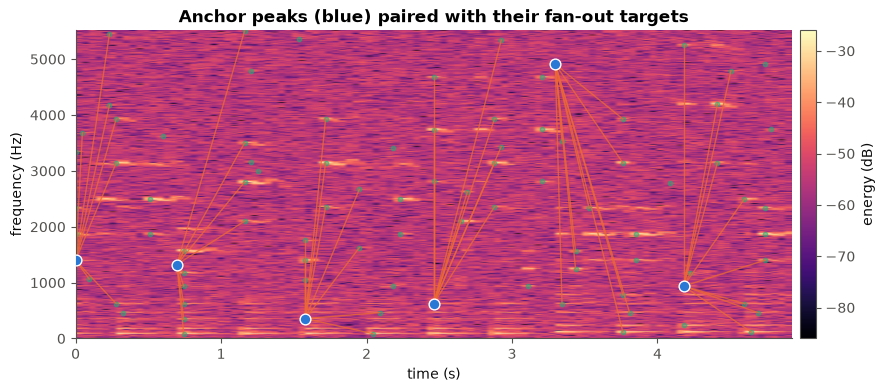

In [12]:
# ✅ Check TODO 2
toy_peaks = np.array([[10, 0], [20, 3], [15, 5], [30, 400]])
got = fingerprint(toy_peaks, fan_out=2, max_dt=200)
expected = [((10, 20, 3), 0), ((10, 15, 5), 0), ((20, 15, 2), 3)]
assert sorted(got) == sorted(expected), f"expected {expected}\n got      {got}"

query_hashes = fingerprint(query_peaks)
print(f"✅ fingerprint works! The query has {len(query_hashes)} hashes, e.g. {query_hashes[:2]}")

# Visualize the anchor -> target-zone pairs for a few anchors
fig, ax = plt.subplots(figsize=(11, 4))
plot_spectrogram(S_query, "Anchor peaks (blue) paired with their fan-out targets", ax)
ax.scatter(query_peaks[:, 1] * FRAME_SEC, query_peaks[:, 0] * FS / NPERSEG, s=10, c=AQUA, alpha=0.5)
for i in range(0, len(query_peaks), max(1, len(query_peaks) // 6))[:6]:
    f1, t1 = query_peaks[i]
    for f2, t2 in query_peaks[i + 1:i + 11]:
        ax.plot(np.array([t1, t2]) * FRAME_SEC, np.array([f1, f2]) * FS / NPERSEG, c=ORANGE, lw=1, alpha=0.8)
    ax.scatter([t1 * FRAME_SEC], [f1 * FS / NPERSEG], s=60, c=BLUE, edgecolors="white", zorder=3)

---
## Part 3 · The database and offset voting

The database is an **inverted index**: a dict mapping **hash → list of (song_id, t_anchor)**. A lookup takes O(1) time no matter how many songs are stored. This cell builds it for the whole library:

In [13]:
def build_database(songs):
    db = defaultdict(list)
    for song_id, x in enumerate(songs):
        for key, t_anchor in fingerprint(find_peaks(compute_spectrogram(x)[2])):
            db[key].append((song_id, t_anchor))
    return db

db = build_database(songs)
print(f"{len(db):,} distinct hashes, {sum(len(v) for v in db.values()):,} entries for {len(songs)} songs")

27,729 distinct hashes, 33,436 entries for 8 songs


### The key idea: real matches agree on a time offset

Suppose a query hash at time $t_q$ matches a song hash at time $t_s$. For a **real** match, $t_s - t_q$ is where the clip starts in the song, and that value is **the same for every real match**. Coincidental matches (songs share notes!) produce random offsets.

So each matching hash **votes** for `(song_id, offset)`, and the tallest pile of votes wins.

### ✏️ TODO 3: `vote`
For each `(key, t_q)` in the query, and for each `(song_id, t_s)` in `db.get(key, [])`, add one vote to `votes[song_id][t_s - t_q]`.

*(`votes[song_id]` is a `Counter`, so `+= 1` just works.)*

In [14]:
def vote(query_hashes, db):
    """Return {song_id: Counter({offset: n_votes})}."""
    votes = defaultdict(Counter)
    for key, t_q in query_hashes:
        for song_id, t_s in db.get(key, []):
            votes[song_id][t_s - t_q] += 1
    return votes

> Why do we do `votes[song_id][t_s - t_q]` instead of doing the scatterplot of query-song matches and finding diagonal line? 

This is essentially the same thing, the idea is that if two songs are the same, the sample and query should match pretty frequently for the same `t_s - t_q` since the offset will remain constant between the song and query sample.

In [15]:
# ✅ Check TODO 3
toy_db = {(1, 2, 3): [(0, 10), (1, 99)], (4, 5, 6): [(0, 11)]} # each (f_1, f_2, ∆t) is as good as a hashed version of it in this dict
toy_votes = vote([((1, 2, 3), 5), ((4, 5, 6), 6)], toy_db)
assert toy_votes[0] == Counter({5: 2}) and toy_votes[1] == Counter({94: 1}), dict(toy_votes)
print("✅ vote works!")

def identify(clip):
    """Full pipeline: audio -> peaks -> hashes -> votes -> ranked [(song_id, score, offset_sec)]."""
    votes = vote(fingerprint(find_peaks(compute_spectrogram(clip)[2])), db)
    ranked = [(sid, *reversed(c.most_common(1)[0])) for sid, c in votes.items()]
    return sorted(((sid, score, off * FRAME_SEC) for sid, score, off in ranked), key=lambda r: -r[1])

ranked = identify(query)
song_id, score, offset = ranked[0]
print(f"\n🎵 It's '{SONG_NAMES[song_id]}', starting at {offset:.1f} s   (score {score})")
print(f"   truth: '{SONG_NAMES[SECRET_SONG]}' at {SECRET_START} s")

✅ vote works!

🎵 It's 'Fourier Nights', starting at 5.3 s   (score 141)
   truth: 'Fourier Nights' at 5.3 s


### 💡 Why it works

**Left:** each matching hash plotted at (query time, song time). For the true song, the real matches fall on a **diagonal**. **Right:** the histogram of `t_s − t_q`, where that diagonal becomes **one spike**.

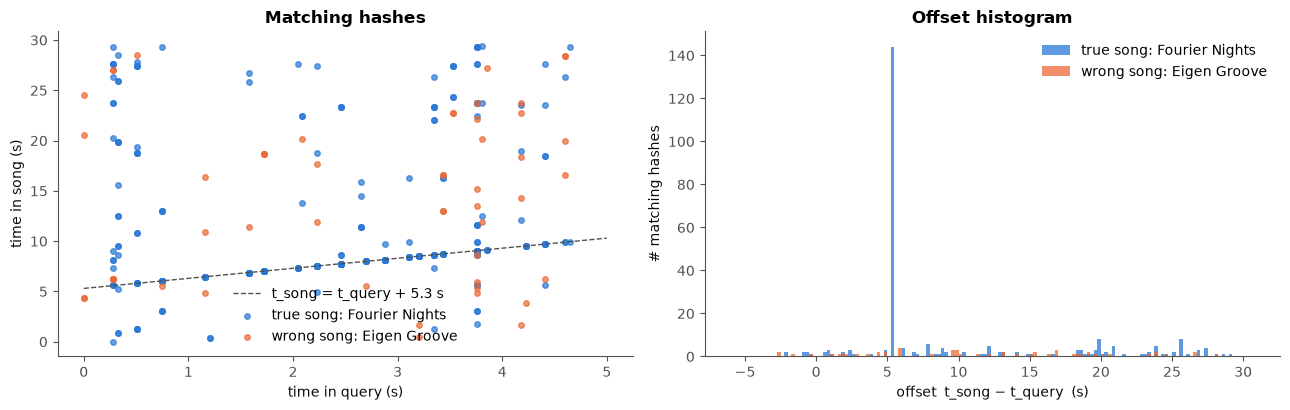

In [16]:
def plot_match(clip, song_ids, labels, true_offset=None):
    q_hashes = fingerprint(find_peaks(compute_spectrogram(clip)[2]))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
    if true_offset is not None:
        qt = np.array([0, len(clip) / FS])
        ax1.plot(qt, qt + true_offset, ls="--", lw=1, c=GREY, label=f"t_song = t_query + {true_offset:.1f} s")
    for sid, color, label in zip(song_ids, [BLUE, ORANGE], labels):
        pts = np.array([(t_q, t_s) for key, t_q in q_hashes
                        for s, t_s in db.get(key, []) if s == sid]) * FRAME_SEC
        if len(pts) == 0:
            continue
        ax1.scatter(pts[:, 0], pts[:, 1], s=16, c=color, alpha=0.7, label=label)
        ax2.hist(pts[:, 1] - pts[:, 0], bins=np.arange(-6, SONG_SECONDS + 1, 0.25), color=color, alpha=0.75, label=label)
    ax1.set(xlabel="time in query (s)", ylabel="time in song (s)", title="Matching hashes")
    ax2.set(xlabel="offset  t_song − t_query  (s)", ylabel="# matching hashes", title="Offset histogram")
    for ax in (ax1, ax2):
        ax.legend(frameon=False)
    plt.tight_layout()

ids, labels = [SECRET_SONG], [f"true song: {SONG_NAMES[SECRET_SONG]}"]
wrong = next((sid for sid, _, _ in ranked if sid != SECRET_SONG), None)   # best-scoring wrong song, if any
if wrong is not None:
    ids.append(wrong)
    labels.append(f"wrong song: {SONG_NAMES[wrong]}")
plot_match(query, ids, labels, true_offset=SECRET_START)

### 🗣 Discuss
- The wrong song also has some hash hits. Why don't they matter? *(They don't **agree** on an offset. Alignment is the evidence, not the hit count.)*
- Why does the true song have a few smaller spikes too? *(Music repeats: a chorus produces the same hashes at different times.)*

---
## Part 4 · Stress test

Now attack it with harder clips: a **phone** recording (300–3400 Hz band-limit + room echo + noise), noise **3× louder than the music** (−10 dB), a song **not in the library**, and a clip **sped up 5%**.

In [17]:
def phone_mic(x, snr_db=5, rng=0):
    """Simulate playing through a speaker into a phone: bandpass + room reverb + noise."""
    r = np.random.default_rng(rng)
    x = sosfiltfilt(butter(4, [300, 3400], btype="band", fs=FS, output="sos"), x)
    room = r.standard_normal(int(0.3 * FS)) * np.exp(-np.arange(int(0.3 * FS)) / (0.06 * FS))
    room[0] = 8                                                     # direct path
    return add_noise(fftconvolve(x, room)[:len(x)], snr_db, r)

stranger = make_song(seed=999)[int(5 * FS):int(10 * FS)]
tests = {
    "clean":           (1, songs[1][int(20 * FS):int(25 * FS)]),
    "phone":           (2, phone_mic(songs[2][int(14 * FS):int(19 * FS)])),
    "very noisy":      (6, make_query(6, 3.1, snr_db=-10, rng=3)),
    "not in library":  (None, add_noise(stranger, 0, 4)),
    "sped up 5%":      (4, resample(songs[4][int(9 * FS):int(14.25 * FS)], 5 * FS)),
}

print(f"{'clip':<16} {'truth':<18} {'prediction':<18} {'score':>5} {'runner-up':>9}")
print("-" * 70)
for name, (truth, clip) in tests.items():
    ranked = identify(clip) + [(None, 0, 0), (None, 0, 0)]
    (pred, s1, _), (_, s2, _) = ranked[0], ranked[1]
    truth_name = SONG_NAMES[truth] if truth is not None else "(none)"
    print(f"{name:<16} {truth_name:<18} {SONG_NAMES[pred] if pred is not None else '(none)':<18} {s1:>5} {s2:>9}")

play(tests["phone"][1])     # 🎧 what the "phone" clip sounds like

clip             truth              prediction         score runner-up
----------------------------------------------------------------------
clean            Nyquist Shuffle    Nyquist Shuffle      202         8
phone            Aliasing Blues     Aliasing Blues        46         2
very noisy       Eigen Groove       Eigen Groove          39         3
not in library   (none)             Phase-Locked Love      1         1
sped up 5%       Bode to Joy        Lowpass Lullaby        1         1


### 🗣 Discuss
- The algorithm *always* returns a best guess. Looking at the scores, how would you decide to answer **"no match"**?
- Why does a 5% speed-up break it completely? *(Every frequency bin and every Δt shifts, so no hash matches exactly.)*

**🔧 If you finish early:** find the noise level or clip length where it breaks, or record a song from this notebook on your phone, upload it, and run `identify(load_audio("your_file.m4a", seconds=10))`.

---
## Wrap-up

```
audio → spectrogram → peaks → peak-pair hashes (f1, f2, Δt) → inverted index
query → hashes → look up → vote on (song, t_song − t_query) → tallest spike wins
```

Real Shazam does the same thing at scale: it packs hashes into 32-bit ints and shards the index across machines. Read the original 4-page paper: Avery Wang, [*An Industrial-Strength Audio Search Algorithm*](https://www.ee.columbia.edu/~dpwe/papers/Wang03-shazam.pdf), ISMIR 2003.